<a href="https://colab.research.google.com/github/ttobias28/PhishRadar-Project/blob/main/PhishRadar_DistilBERT_SourceInvariant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PhishRadar — Experiment A: Source-invariant DistilBERT

**Authors:** Connor Buttrey, Oliver Conley, Robert Morriss, Ashley Smutnik, Teagan Tobias

<br>

**The question:** the model trains on only three collections (Enron, Ling, SpamAssassin), and each has its own writing style *and* its own share of phishing (Enron ~47%, SpamAssassin ~26%, Ling ~16%). So "which collection does this email look like?" is a shortcut that partly predicts the label. Shortcuts like that don't carry over to new sources such as CEAS or Nazario. **If the shortcut is taken away, do the cross-source scores improve?**

**Three versions are trained with identical settings, data and random seed:**

| Version | What changes |
|---|---|
| `baseline` | Plain fine-tuning, same as the main notebook. The control. |
| `balanced` | Each (source, label) combination counts equally in training, so the source no longer predicts the label. |
| `source_invariant` | Balanced **plus** an adversary: a small extra network tries to guess the source from BERT's internal summary of the email, and BERT is trained to make it fail. |

Comparing `balanced` with `source_invariant` shows whether the adversary adds anything beyond balancing. All three are scored on the same five test sets as the main notebook.

**Every time (Google Colab):**
1. Open this notebook in Colab (colab.research.google.com → **File → Upload notebook**).
2. **Runtime → Change runtime type → T4 GPU**.
3. Put the split CSVs (built by `src/make_splits.py`, see `data/README.md`) in `MyDrive/phishradar/data/splits/` in your Google Drive. All notebooks in this repository read them from there.
4. **Runtime → Run all**, allow the Google Drive connection when asked, and keep the tab open. The settings in step 3 are the final ones, so with all three versions on the full data expect roughly 1.5–2 hours.
5. At the end, the results are saved to `MyDrive/phishradar/results/` (section 15), including `si_run_config.json`, which records exactly which settings produced them.

The repository `README.md` has the full run order and the results of this experiment.

**Quick check first (optional):** set `SAMPLE_SIZE = 5000` (about 15 minutes) to make sure everything works, then set it back to `None` for the real run.

**Honest-reporting rule:** the test sets are for reporting, not tuning. Do not change `ADV_WEIGHT` after looking at test scores. If you try several values, record every one and say which was used.


## Run log
Every run of this experiment, in order. **Only the last row's results are reported.** Rows 1–3 are kept so that what was tried is on record.

| # | Run | Data | Versions | Adversary settings | Probe | What changed and why |
|---|---|---|---|---|---|---|
| 1 | Quick check | 5,000 train emails | baseline, balanced, source_invariant | `ADV_WEIGHT` 1.0, `ADV_LR` 5e-4, one hidden layer (256) | all labels together | First run, to check the code works. |
| 2 | Quick check | 5,000 train emails | baseline, source_invariant | `ADV_WEIGHT` 1.0, `ADV_LR` 1e-3, two hidden layers (512, 512) | within each label | In run 1 the adversary fell to chance during training, but the source probe (validation set) was unchanged (0.789 vs 0.796), so the adversary was strengthened and the probe was made to match the adversary's within-label design. Run 1's quick-run test scores were visible when this change was made. |
| 3 | Full run | all 30,217 train emails | all three | same as run 2 | within each label | Added ROC AUC. Nothing else changed. |
| 4 | **Full rerun (this notebook)** | all 30,217 train emails | all three | same as runs 2–3 | within each label | Same model settings as run 3. Adds McNemar tests, bootstrap confidence intervals, the standard prediction-file format and a saved run config. Reproduced run 3 exactly: every prediction, score and probe value is identical. |

**`ADV_WEIGHT` was 1.0 in every run and was never changed.** The only tuning was the adversary's learning rate and size (run 1 → 2), judged on the validation-set probe and the training log, not chosen to maximize test scores. Test scores from the quick run were visible at the time, so the choice was not made fully blind to the test sets. No settings were changed after looking at full-run results.

## 1. Install libraries

In [ ]:
%pip install -q transformers datasets accelerate scikit-learn seaborn

## 2. Imports and GPU check

In [ ]:
import os, re, sys, glob, zipfile, math, shutil, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_fscore_support, accuracy_score,
                             confusion_matrix, balanced_accuracy_score)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

IN_COLAB = "google.colab" in sys.modules
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_FP16 = device.type == "cuda"
print("Running in Colab:", IN_COLAB)
print("Device:", torch.cuda.get_device_name(0) if USE_FP16 else "CPU (no GPU! Runtime -> Change runtime type -> T4 GPU)")

Running in Colab: True
Device: Tesla T4


## 3. Settings
The first block uses the same settings as the main notebook.

**Why this `baseline` doesn't exactly match the main DistilBERT run:** it's a **separate retrain on the same rows** (same split files, same `row_id`s), not a different row set. This notebook needs its own training loop for the adversary, and that loop differs from the main notebook's Hugging Face `Trainer` in small ways:
- it keeps the model from the **last** epoch, while the main notebook keeps whichever epoch had the best validation F1;
- it warms the learning rate up over the first 6% of steps (the `Trainer` default is no warm-up);
- it applies weight decay to all weights (the `Trainer` skips biases and LayerNorm);
- it shuffles the training data in a different order, and the classifier head starts from different random values.

So expect differences of about a point. **Compare the three versions in this notebook with each other**; the main notebook's run stays the official DistilBERT result in the three-way comparison. The size of the gap between the two baselines is itself a rough guide to run-to-run noise.

The second block is new:
- **VARIANTS**: which versions to train, in order.
- **ADV_WEIGHT**: how hard BERT is pushed to hide the source (0 = not at all). 1.0 is a standard starting point. If you change it, judge the change on the validation set and the source probe, **not** on the test scores, and write down every value you tried.
- **ADV_LR**: learning rate for the adversary. It starts from scratch, so it learns faster than BERT.
- **MAX_WEIGHT**: cap on how much one rare email can count when balancing (e.g. Ling's few phishing emails), so a handful of emails can't dominate training.
- **SAVE_VARIANT**: which trained model to save at the end (to `MyDrive/phishradar/models/`).
- **RUN_ID**: a label for this run. It's saved in `si_run_config.json` so every result file can be traced back to the run log above. Change it if you run again.
- **N_BOOT**: how many bootstrap resamples to use for the confidence intervals (1,000 is standard).

In [ ]:
MODEL_NAME        = "distilbert-base-uncased"
MAX_LENGTH        = 256
EPOCHS            = 2
LEARNING_RATE     = 2e-5
BATCH_SIZE        = 16
SEED              = 42
SAMPLE_SIZE       = None    # None = full training set (final run). Use 5000 for a quick check.
NORMALIZE_SPACING = True

VARIANTS          = ["baseline", "balanced", "source_invariant"]
ADV_WEIGHT        = 1.0     # strength of the adversary; 1.0 was used for the reported run
ADV_LR            = 1e-3
MAX_WEIGHT        = 10.0
SAVE_VARIANT      = "source_invariant"
DOWNLOAD_MODEL    = True    # True = also save the trained model (~250 MB) to Drive
RUN_ID            = "A-run4-full"   # matches row 4 of the run log
N_BOOT            = 1000

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/phishradar"
    DATA_DIR = BASE + "/data/splits"
else:
    BASE = "."
    DATA_DIR = "data"
OUT_DIR = "/content" if IN_COLAB else "."
TEST_SETS = ["test_insource", "test_ceas", "test_nazario_paired", "test_nazario", "test_nigerian"]

## 4. Load the data
In Colab, this cell reads the splits from `MyDrive/phishradar/data/splits/` (see the steps at the top). In plain Jupyter it reads a folder called `data` next to this notebook; `train.csv` is found in any subfolder.

In [ ]:
found = glob.glob(os.path.join(DATA_DIR, "**", "train.csv"), recursive=True)
if not found:
    raise FileNotFoundError(f"train.csv not found in '{DATA_DIR}'. In Colab, put the split CSVs in MyDrive/phishradar/data/splits/ "
                            "and rerun. In plain Jupyter, put them in a folder called 'data' next to this notebook.")
DATA_DIR = os.path.dirname(found[0])

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df   = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
tests    = {name: pd.read_csv(os.path.join(DATA_DIR, f"{name}.csv")) for name in TEST_SETS}

print(f"{'train':>20}: {len(train_df):>6,} emails, {train_df.label.mean():.0%} phishing")
print(f"{'val':>20}: {len(val_df):>6,} emails, {val_df.label.mean():.0%} phishing")
for name, d in tests.items():
    print(f"{name:>20}: {len(d):>6,} emails, {d.label.mean():.0%} phishing")

               train: 30,217 emails, 42% phishing
                 val:  3,778 emails, 42% phishing
       test_insource:  3,778 emails, 42% phishing
           test_ceas: 38,748 emails, 55% phishing
 test_nazario_paired:  3,088 emails, 50% phishing
        test_nazario:  1,544 emails, 100% phishing
       test_nigerian:  3,243 emails, 100% phishing


## 5. Fix the spaced-punctuation quirk
Same fix as the main notebook: Enron and Ling were stored as `doesn ' t , and`, while every test source uses normal punctuation. This removes the most obvious style difference before the model ever sees it.

In [ ]:
def normalize_spacing(t):
    t = re.sub(r"(\w) ' (s|t|re|ve|ll|d|m)\b", r"\1'\2", t)   # doesn ' t -> doesn't
    t = re.sub(r"\s+([,.;:!?%)\]}])", r"\1", t)                # word , -> word,
    t = re.sub(r"([(\[{$])\s+", r"\1", t)                      # ( word -> (word
    t = re.sub(r"(\d) ([.,:/]) (\d)", r"\1\2\3", t)             # 6 / 10 -> 6/10
    t = re.sub(r"(\d)([.,:/]) (\d)", r"\1\2\3", t)
    return t

if NORMALIZE_SPACING:
    for d in [train_df, val_df, *tests.values()]:
        d["text"] = d["text"].map(normalize_spacing)

if SAMPLE_SIZE:
    train_df = train_df.sample(n=min(SAMPLE_SIZE, len(train_df)), random_state=SEED)
    val_df   = val_df.sample(n=min(SAMPLE_SIZE // 5, len(val_df)), random_state=SEED)
print(f"Training on {len(train_df):,} emails, validating on {len(val_df):,}")

Training on 30,217 emails, validating on 3,778


## 6. The shortcut, in numbers
This table is the problem in one picture: the share of phishing differs a lot by source, so a model that recognizes the source can guess the label without understanding phishing.

In [ ]:
shortcut = train_df.groupby("source").label.agg(emails="size", phishing_share="mean").round(3)
shortcut

,emails,phishing_share
source,,
Enron,23470,0.474
Ling,2278,0.165
SpamAssassin,4469,0.263


## 7. Balancing weights
Each email gets a weight so that every (source, label) combination counts the same in total. After weighting, every source is effectively 50% phishing, so knowing the source tells the model (almost) nothing about the label.

Rare combinations (like Ling phishing) get big weights; `MAX_WEIGHT` caps them, so Ling phishing ends up somewhat under-weighted: the balance is approximate, not exact. The table shows each combination's total weight after balancing; they should come out roughly equal.

In [ ]:
TRAIN_SOURCES = sorted(train_df.source.unique())
src2id = {s: i for i, s in enumerate(TRAIN_SOURCES)}

cell_size = train_df.groupby(["source", "label"])["label"].transform("size")
w = 1.0 / cell_size
w = w / w.mean()
w = w.clip(upper=MAX_WEIGHT)
train_df["weight"] = w / w.mean()
train_df["source_id"] = train_df.source.map(src2id)

train_df.groupby(["source", "label"]).weight.agg(emails="size", weight_each="mean", total_weight="sum").round(2)

emails  weight_each  total_weight
source       label                                   
Enron        0       12340         0.43       5256.42
             1       11130         0.47       5256.42
Ling         0        1901         2.77       5256.42
             1         377        10.44       3934.88
SpamAssassin 0        3294         1.60       5256.42
             1        1175         4.47       5256.42

## 8. Tokenize
Same as the main notebook. The training set also carries each email's `weight` and `source_id` for the new training loop.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tokenizer)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

def to_dataset(frame, extra=()):
    ds = Dataset.from_pandas(frame[["text", "label", *extra]], preserve_index=False)
    return ds.map(tokenize, batched=True, remove_columns=["text"])

train_ds = to_dataset(train_df, extra=("weight", "source_id"))
val_ds   = to_dataset(val_df)
test_ds  = {name: to_dataset(d) for name, d in tests.items()}
train_ds

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/30217 [00:00<?, ? examples/s]

Map:   0%|          | 0/3778 [00:00<?, ? examples/s]

... (2 outputs left out)

Map:   0%|          | 0/3088 [00:00<?, ? examples/s]

Map:   0%|          | 0/1544 [00:00<?, ? examples/s]

Map:   0%|          | 0/3243 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'weight', 'source_id', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 30217
})

## 9. The adversary
Two small pieces of new machinery:

- **Gradient reversal.** On the way forward it does nothing. On the way back (when the model learns), it flips the sign of the learning signal. So the adversary learns to *guess* the source, while BERT, below it, learns to make that guess *harder*.
- **Class-conditional.** The adversary guesses the source **among emails with the same label** (phishing vs. phishing, legit vs. legit). That way BERT hides the source *style* without having to hide whether an email is phishing, which is the part we want it to keep.

The adversary is only used during training. The saved model is a normal DistilBERT classifier that loads exactly like the main notebook's model.

In [ ]:
class GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, strength):
        ctx.strength = strength
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        return -ctx.strength * grad, None


class SourceAdversary(nn.Module):
    def __init__(self, hidden_size, n_sources):
        super().__init__()
        self.n_sources = n_sources
        self.net = nn.Sequential(nn.Linear(hidden_size, 512), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(512, 512), nn.ReLU(), nn.Dropout(0.1),
                                 nn.Linear(512, 2 * n_sources))

    def forward(self, cls_vec, labels, strength):
        logits = self.net(GradReverse.apply(cls_vec, strength)).view(-1, 2, self.n_sources)
        return logits[torch.arange(len(labels), device=labels.device), labels]   # guess within the true label

## 10. Scoring helpers
Same metrics as the main notebook, plus a function that runs a model over a dataset and returns its phishing probabilities.

In [ ]:
def score(labels, preds):
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1,
            "false_positive_rate": fp / (fp + tn) if (fp + tn) else float("nan")}

@torch.no_grad()
def run_model(model, ds, want_embeddings=False):
    model.eval()
    loader = DataLoader(ds.select_columns(["input_ids", "attention_mask"]),
                        batch_size=128, collate_fn=collator)
    probs, embs = [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_FP16):
            out = model(**batch, output_hidden_states=want_embeddings)
        probs.append(torch.softmax(out.logits.float(), dim=-1)[:, 1].cpu().numpy())
        if want_embeddings:
            embs.append(out.hidden_states[-1][:, 0].float().cpu().numpy())
    probs = np.concatenate(probs)
    return (probs, np.concatenate(embs)) if want_embeddings else probs

## 11. The training loop
One function trains any of the three versions:
- `baseline`: every email counts the same; no adversary.
- `balanced`: uses the weights from step 7; no adversary.
- `source_invariant`: weights **and** adversary. The adversary's strength ramps up from 0 to `ADV_WEIGHT` during training, so BERT first learns the task and then learns to hide the source.

Every 200 steps it prints the task loss and, for `source_invariant`, the adversary's **balanced accuracy** at guessing the source (chance is about 0.33 with three sources). If BERT is hiding the source well, that number drifts down toward chance over training.

Each version starts from the same pre-trained DistilBERT and the same random seed, so the only difference is the training method.

In [ ]:
def train_variant(name):
    use_weights = name in ("balanced", "source_invariant")
    use_adv = name == "source_invariant"
    torch.manual_seed(SEED); np.random.seed(SEED)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label={0: "legit", 1: "phishing"}, label2id={"legit": 0, "phishing": 1}).to(device)
    adversary = SourceAdversary(model.config.hidden_size, len(TRAIN_SOURCES)).to(device)

    groups = [{"params": model.parameters(), "lr": LEARNING_RATE}]
    if use_adv:
        groups.append({"params": adversary.parameters(), "lr": ADV_LR})
    optimizer = torch.optim.AdamW(groups, weight_decay=0.01)

    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator,
                        generator=torch.Generator().manual_seed(SEED))
    total_steps = EPOCHS * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_FP16)

    step, start = 0, time.time()
    for epoch in range(EPOCHS):
        model.train(); adversary.train()
        log = {"task": 0.0, "adv": 0.0, "hit": 0.0, "wsum": 0.0, "n": 0}
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch["labels"]
            weights = batch["weight"].float() if use_weights else torch.ones_like(labels, dtype=torch.float)
            strength = ADV_WEIGHT * (2 / (1 + math.exp(-10 * step / total_steps)) - 1)

            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_FP16):
                out = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                            output_hidden_states=use_adv)
            task_loss = (F.cross_entropy(out.logits.float(), labels, reduction="none") * weights).mean()
            loss = task_loss
            if use_adv:
                cls_vec = out.hidden_states[-1][:, 0].float()
                src_logits = adversary(cls_vec, labels, strength)
                adv_loss = (F.cross_entropy(src_logits, batch["source_id"], reduction="none") * weights).mean()
                loss = loss + adv_loss
                hit = (src_logits.argmax(-1) == batch["source_id"]).float()
                log["adv"] += adv_loss.item(); log["hit"] += (hit * weights).sum().item(); log["wsum"] += weights.sum().item()

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(list(model.parameters()) + list(adversary.parameters()), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            step += 1; log["task"] += task_loss.item(); log["n"] += 1

            if step % 200 == 0 or step == total_steps:
                msg = f"  [{name}] step {step}/{total_steps}  task loss {log['task'] / log['n']:.4f}"
                if use_adv:
                    msg += f"  | adversary source accuracy {log['hit'] / max(log['wsum'], 1e-9):.2f} (strength {strength:.2f})"
                print(msg + f"  | {(time.time() - start) / 60:.1f} min", flush=True)
                log = {"task": 0.0, "adv": 0.0, "hit": 0.0, "wsum": 0.0, "n": 0}

        val_probs = run_model(model, val_ds)
        m = score(val_df.label.values, (val_probs >= 0.5).astype(int))
        print(f"  [{name}] epoch {epoch + 1}: validation F1 {m['f1']:.4f}, accuracy {m['accuracy']:.4f}", flush=True)
    return model

## 12. Train and score every version
For each version this cell: trains it, scores all five test sets, and runs a **source probe**. The probe takes BERT's internal summary of each validation email and checks how well a simple classifier can still tell which source it came from (balanced accuracy, chance ≈ 0.33). A lower probe score means the model really did stop encoding the source.

This is the long cell. Keep the tab open and your computer awake.

In [ ]:
from sklearn.metrics import roc_auc_score
rows, all_preds, probe_rows = [], [], []
for name in VARIANTS:
    print(f"\n=== Training {name} ===")
    model = train_variant(name)

    for test_name, d in tests.items():
        probs = run_model(model, test_ds[test_name])
        preds = (probs >= 0.5).astype(int)
        m = score(d.label.values, preds)
        if d.label.nunique() == 1:                       # phishing-only set: only recall is meaningful
            m.update(precision=float("nan"), f1=float("nan"))
        else:
            m["roc_auc"] = roc_auc_score(d.label.values, probs)   # threshold-free ranking quality
        rows.append({"variant": name, "test_set": test_name, "emails": len(d), **m})
        all_preds.append(pd.DataFrame({"variant": name, "test_set": test_name, "row": np.arange(len(d)),
                                       "label": d.label.values, "source": d.source.values,
                                       "pred": preds, "phish_prob": probs}))

    _, emb = run_model(model, val_ds, want_embeddings=True)
    probe_scores = []
    for lab in (0, 1):                                   # probe within each label, like the adversary
        mask = val_df.label.values == lab
        e_tr, e_te, s_tr, s_te = train_test_split(emb[mask], val_df.source.values[mask], test_size=0.5,
                                                  stratify=val_df.source.values[mask], random_state=SEED)
        probe = LogisticRegression(max_iter=2000, class_weight="balanced").fit(e_tr, s_tr)
        probe_scores.append(balanced_accuracy_score(s_te, probe.predict(e_te)))
    probe_rows.append({"variant": name, "source_probe_balanced_acc": float(np.mean(probe_scores))})
    print(f"  [{name}] source probe balanced accuracy: {probe_rows[-1]['source_probe_balanced_acc']:.3f}")

    if name == SAVE_VARIANT:
        save_dir = os.path.join(OUT_DIR, f"distilbert-{name.replace('_', '-')}")
        model.save_pretrained(save_dir); tokenizer.save_pretrained(save_dir)
        print("  Saved model to", save_dir)
    del model
    if USE_FP16:
        torch.cuda.empty_cache()

results = pd.DataFrame(rows)
predictions = pd.concat(all_preds, ignore_index=True)
probe_table = pd.DataFrame(probe_rows).set_index("variant").round(3)
print("\nDone.")


=== Training baseline ===


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [baseline] step 200/3778  task loss 0.3971  | 0.4 min
  [baseline] step 400/3778  task loss 0.1223  | 0.7 min
  [baseline] step 600/3778  task loss 0.0888  | 1.1 min
  [baseline] step 800/3778  task loss 0.0677  | 1.5 min
  [baseline] step 1000/3778  task loss 0.0648  | 1.8 min
  [baseline] step 1200/3778  task loss 0.0698  | 2.2 min
  [baseline] step 1400/3778  task loss 0.0498  | 2.6 min
  [baseline] step 1600/3778  task loss 0.0523  | 3.0 min
  [baseline] step 1800/3778  task loss 0.0571  | 3.4 min
  [baseline] epoch 1: validation F1 0.9890, accuracy 0.9907
  [baseline] step 2000/3778  task loss 0.0194  | 3.9 min
  [baseline] step 2200/3778  task loss 0.0256  | 4.3 min
  [baseline] step 2400/3778  task loss 0.0293  | 4.7 min
  [baseline] step 2600/3778  task loss 0.0206  | 5.1 min
  [baseline] step 2800/3778  task loss 0.0134  | 5.5 min
  [baseline] step 3000/3778  task loss 0.0193  | 5.9 min
  [baseline] step 3200/3778  task loss 0.0136  | 6.3 min
  [baseline] step 3400/3778  tas

... (4 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [source_invariant] step 200/3778  task loss 0.4766  | adversary source accuracy 0.50 (strength 0.26)  | 0.4 min
  [source_invariant] step 400/3778  task loss 0.1527  | adversary source accuracy 0.36 (strength 0.48)  | 0.8 min
  [source_invariant] step 600/3778  task loss 0.0999  | adversary source accuracy 0.37 (strength 0.66)  | 1.2 min
  [source_invariant] step 800/3778  task loss 0.0959  | adversary source accuracy 0.35 (strength 0.78)  | 1.7 min
  [source_invariant] step 1000/3778  task loss 0.0800  | adversary source accuracy 0.36 (strength 0.87)  | 2.1 min
  [source_invariant] step 1200/3778  task loss 0.0558  | adversary source accuracy 0.35 (strength 0.92)  | 2.5 min
  [source_invariant] step 1400/3778  task loss 0.0710  | adversary source accuracy 0.36 (strength 0.95)  | 2.9 min
  [source_invariant] step 1600/3778  task loss 0.0854  | adversary source accuracy 0.34 (strength 0.97)  | 3.3 min
  [source_invariant] step 1800/3778  task loss 0.0575  | adversary source accuracy 0

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  Saved model to /content/distilbert-source-invariant

Done.


## 13. Results side by side
**How to read this table:** each column is a version, each row a test set. The number is **F1** for the mixed test sets, and **recall** (detection rate) for the phishing-only sets (`test_nazario`, `test_nigerian`), where F1 doesn't apply.

What would support the idea: `source_invariant` (and/or `balanced`) beating `baseline` on the cross-source rows (`test_ceas`, `test_nazario_paired`, `test_nazario`, `test_nigerian`), even if `test_insource` drops slightly. A small in-source drop is expected: the shortcut *did* help on the training sources.

Also check the false-positive rates below: a model can raise recall just by flagging more emails as phishing. **ROC AUC** ignores the 0.5 cutoff, so it separates "ranks emails worse" from "just more (or less) cautious".

In [ ]:
results["headline"] = np.where(results.f1.isna(), results.recall, results.f1)
headline = results.pivot(index="test_set", columns="variant", values="headline").reindex(index=TEST_SETS, columns=VARIANTS).round(4)
fpr = results.pivot(index="test_set", columns="variant", values="false_positive_rate").reindex(index=TEST_SETS, columns=VARIANTS).round(4)
print("F1 (mixed sets) / recall (phishing-only sets):")
display(headline)
print("\nFalse-positive rate (lower is better; blank = no legit emails in that set):")
display(fpr.dropna(how="all"))
auc = results.pivot(index="test_set", columns="variant", values="roc_auc").reindex(index=TEST_SETS, columns=VARIANTS).round(4)
print("\nROC AUC (ignores the 0.5 cutoff; 1.0 = phishing always scored above legit):")
display(auc.dropna(how="all"))
print("\nSource probe (lower = less source information left; chance is about 0.33):")
display(probe_table)

F1 (mixed sets) / recall (phishing-only sets):


variant,baseline,balanced,source_invariant
test_set,,,
test_insource,0.9893,0.9899,0.9861
test_ceas,0.8990,0.8919,0.8895
test_nazario_paired,0.8712,0.8701,0.8527
test_nazario,0.8238,0.8199,0.7947
test_nigerian,0.9938,0.9935,0.9932



False-positive rate (lower is better; blank = no legit emails in that set):


variant,baseline,balanced,source_invariant
test_set,,,
test_insource,0.0078,0.0078,0.0105
test_ceas,0.0621,0.0637,0.0662
test_nazario_paired,0.0674,0.0648,0.0693



ROC AUC (ignores the 0.5 cutoff; 1.0 = phishing always scored above legit):


variant,baseline,balanced,source_invariant
test_set,,,
test_insource,0.9996,0.9993,0.9989
test_ceas,0.9759,0.9732,0.9742
test_nazario_paired,0.9584,0.9577,0.9544



Source probe (lower = less source information left; chance is about 0.33):


,source_probe_balanced_acc
variant,
baseline,0.791
balanced,0.766
source_invariant,0.792


## 14. Chart

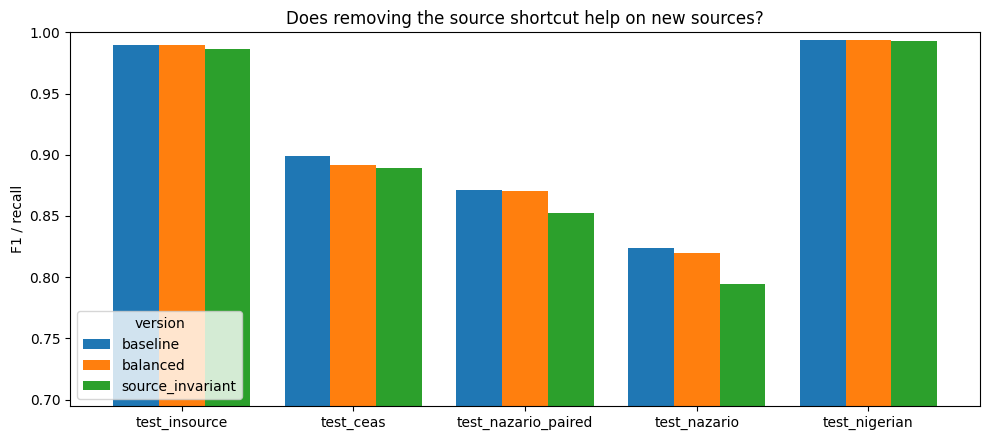

In [ ]:
ax = headline.plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylabel("F1 / recall"); ax.set_xlabel("")
ax.set_ylim(max(0, headline.min().min() - 0.1), 1.0)
ax.set_title("Does removing the source shortcut help on new sources?")
ax.legend(title="version", loc="lower left")
plt.tight_layout(); plt.show()

### Is any difference real? (McNemar test vs. baseline)
For each test set, count the emails where only one of the two versions is right and test whether those counts are lopsided (exact McNemar test, the same test the comparison notebook uses). With one random seed and differences of about a point, a p-value above 0.05 means the difference could be noise.

In [ ]:
from scipy.stats import binomtest

def mcnemar_vs(base, other):
    a, b = base.pred.values == base.label.values, other.pred.values == other.label.values
    only_base, only_other = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(min(only_base, only_other), only_base + only_other, 0.5).pvalue if only_base + only_other else 1.0
    return only_base, only_other, p

mc_rows = []
for t in TEST_SETS:
    base = predictions[(predictions.variant == "baseline") & (predictions.test_set == t)].sort_values("row")
    for v in VARIANTS:
        if v == "baseline":
            continue
        oth = predictions[(predictions.variant == v) & (predictions.test_set == t)].sort_values("row")
        ob, oo, p = mcnemar_vs(base, oth)
        mc_rows.append({"test_set": t, "variant": v, "only baseline right": ob, "only variant right": oo, "p-value": round(p, 4)})
mcnemar_table = pd.DataFrame(mc_rows)
mcnemar_table

,test_set,variant,only baseline right,only variant right,p-value
0,test_insource,balanced,7,9,0.8036
1,test_insource,source_invariant,17,7,0.0639
2,test_ceas,balanced,383,116,0.0000
3,test_ceas,source_invariant,502,137,0.0000
4,test_nazario_paired,balanced,49,47,0.9188
5,test_nazario_paired,source_invariant,106,58,0.0002
6,test_nazario,balanced,42,36,0.5716
7,test_nazario,source_invariant,92,47,0.0002
8,test_nigerian,balanced,1,0,1.0000
9,test_nigerian,source_invariant,4,2,0.6875


### Confidence intervals (bootstrap)
McNemar says *whether* two versions differ; confidence intervals say *by how much, give or take*. For each test set this resamples the emails with replacement `N_BOOT` times, recomputes the headline score (F1, or recall for the phishing-only sets) for every version on the **same** resample, and reports the middle 95% range.

- `ci_low` / `ci_high`: 95% interval for that version's score.
- `diff_vs_baseline` with `diff_ci_low` / `diff_ci_high`: 95% interval for the difference from `baseline`. If it contains 0 (`zero_in_diff_ci` = True), the data can't tell the two versions apart.

**What these intervals don't cover:** they capture test-set sampling noise only. Each version was trained once with one seed, so training randomness isn't included; rerunning with other seeds would measure that.

In [ ]:
def headline_metric(y, p, phishing_only):
    tp = np.sum((y == 1) & (p == 1)); fp = np.sum((y == 0) & (p == 1)); fn = np.sum((y == 1) & (p == 0))
    if phishing_only:                                    # recall
        return tp / (tp + fn) if (tp + fn) else np.nan
    return 2 * tp / (2 * tp + fp + fn) if (tp + fp + fn) else np.nan   # F1

rng = np.random.default_rng(SEED)
ci_rows = []
for t in TEST_SETS:
    sub = {v: predictions[(predictions.variant == v) & (predictions.test_set == t)].sort_values("row") for v in VARIANTS}
    y = sub[VARIANTS[0]].label.values
    p = {v: sub[v].pred.values for v in VARIANTS}
    phishing_only = bool((y == 0).sum() == 0)
    point = {v: headline_metric(y, p[v], phishing_only) for v in VARIANTS}
    boots = {v: np.empty(N_BOOT) for v in VARIANTS}
    for b in range(N_BOOT):
        idx = rng.integers(0, len(y), len(y))            # same resample for every version (paired)
        for v in VARIANTS:
            boots[v][b] = headline_metric(y[idx], p[v][idx], phishing_only)
    for v in VARIANTS:
        lo, hi = np.nanpercentile(boots[v], [2.5, 97.5])
        row = {"test_set": t, "metric": "recall" if phishing_only else "f1", "variant": v,
               "value": point[v], "ci_low": lo, "ci_high": hi}
        if v != "baseline" and "baseline" in VARIANTS:
            dlo, dhi = np.nanpercentile(boots[v] - boots["baseline"], [2.5, 97.5])
            row.update(diff_vs_baseline=point[v] - point["baseline"], diff_ci_low=dlo, diff_ci_high=dhi,
                       zero_in_diff_ci=bool(dlo <= 0 <= dhi))
        ci_rows.append(row)

ci_table = pd.DataFrame(ci_rows).round(4)
ci_table

,test_set,metric,variant,value,ci_low,ci_high,diff_vs_baseline,diff_ci_low,diff_ci_high,zero_in_diff_ci
0,test_insource,f1,baseline,0.9893,0.9855,0.9927,NaN,NaN,NaN,NaN
1,test_insource,f1,balanced,0.9899,0.9862,0.9933,0.0006,-0.0018,0.0031,True
2,test_insource,f1,source_invariant,0.9861,0.9817,0.9899,-0.0031,-0.0063,0.0000,True
3,test_ceas,f1,baseline,0.8990,0.8961,0.9024,NaN,NaN,NaN,NaN
4,test_ceas,f1,balanced,0.8919,0.8888,0.8956,-0.0071,-0.0082,-0.0060,False
5,test_ceas,f1,source_invariant,0.8895,0.8864,0.8929,-0.0095,-0.0108,-0.0083,False
6,test_nazario_paired,f1,baseline,0.8712,0.8582,0.8844,NaN,NaN,NaN,NaN
7,test_nazario_paired,f1,balanced,0.8701,0.8563,0.8825,-0.0011,-0.0079,0.0059,True
8,test_nazario_paired,f1,source_invariant,0.8527,0.8382,0.8663,-0.0186,-0.0282,-0.0097,False
9,test_nazario,recall,baseline,0.8238,0.8051,0.8433,NaN,NaN,NaN,NaN


### Summary rows (cross-source table format)
The repository README's cross-source table uses fixed columns (in-source recall / F1 / FPR, CEAS recall / FPR, Nazario recall, Nigerian recall). This prints one row per version in exactly that format, straight from the results above. It is also saved as `si_readme_table.md` for copying; that file is only a convenience and doesn't need to be kept.

In [ ]:
def cell_value(v, t, col):
    return results.loc[(results.variant == v) & (results.test_set == t), col].iloc[0]

readme_names = {"baseline": "DistilBERT, Exp. A baseline (separate retrain)",
                "balanced": "DistilBERT, Exp. A roughly balanced",
                "source_invariant": "DistilBERT, Exp. A source-invariant"}
readme_lines = ["| Approach | In-source recall | In-source F1 | In-source FPR | CEAS recall | CEAS FPR | Nazario recall | Nigerian recall |",
                "|---|---|---|---|---|---|---|---|"]
for v in VARIANTS:
    vals = [cell_value(v, "test_insource", "recall"), cell_value(v, "test_insource", "f1"),
            cell_value(v, "test_insource", "false_positive_rate"), cell_value(v, "test_ceas", "recall"),
            cell_value(v, "test_ceas", "false_positive_rate"), cell_value(v, "test_nazario", "recall"),
            cell_value(v, "test_nigerian", "recall")]
    readme_lines.append(f"| {readme_names.get(v, v)} | " + " | ".join(f"{x:.4f}" for x in vals) + " |")
readme_table = "\n".join(readme_lines)
with open("si_readme_table.md", "w") as fh:
    fh.write(readme_table + "\n")
print(readme_table)

| Approach | In-source recall | In-source F1 | In-source FPR | CEAS recall | CEAS FPR | Nazario recall | Nigerian recall |
|---|---|---|---|---|---|---|---|
| DistilBERT, Exp. A baseline (separate retrain) | 0.9893 | 0.9893 | 0.0078 | 0.8574 | 0.0621 | 0.8238 | 0.9938 |
| DistilBERT, Exp. A roughly balanced | 0.9905 | 0.9899 | 0.0078 | 0.8462 | 0.0637 | 0.8199 | 0.9935 |
| DistilBERT, Exp. A source-invariant | 0.9868 | 0.9861 | 0.0105 | 0.8436 | 0.0662 | 0.7947 | 0.9932 |


## 15. Save results
Everything is saved to Google Drive under `MyDrive/phishradar/` (in plain Jupyter, next to the notebook):
- `results/predictions/distilbert_<version>_<testset>.csv`: **one file per version and test set** in the standard prediction format (`row_id, y_true, y_pred, score`), for example `distilbert_source_invariant_test_ceas.csv`. The comparison notebook picks these up automatically.
- `results/si_results.csv`: every score for every version and test set.
- `results/si_probe.csv`: the source-probe scores.
- `results/si_mcnemar.csv`: the McNemar tests against the baseline.
- `results/si_ci.csv`: the bootstrap confidence intervals.
- `results/si_readme_table.md`: the summary rows from the cell above (a convenience copy).
- `results/si_run_config.json`: the `RUN_ID`, every setting, the date, library versions and GPU used. It ties these files to the run log, so keep it alongside them.
- `models/distilbert-source-invariant/`: the trained model (~250 MB). Keep it on Drive, **not** in the repository. It loads in the main notebook with `LOAD_SAVED_MODEL = True`.

In [ ]:
results.drop(columns="headline").round(4).to_csv("si_results.csv", index=False)
probe_table.to_csv("si_probe.csv")
mcnemar_table.to_csv("si_mcnemar.csv", index=False)
ci_table.to_csv("si_ci.csv", index=False)

# record exactly which settings produced these files
import json, datetime, transformers
from transformers import AutoConfig
run_config = {
    "run_id": RUN_ID,
    "finished_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "settings": {k: globals()[k] for k in ["MODEL_NAME", "MAX_LENGTH", "EPOCHS", "LEARNING_RATE", "BATCH_SIZE", "SEED",
                                           "SAMPLE_SIZE", "NORMALIZE_SPACING", "VARIANTS", "ADV_WEIGHT", "ADV_LR",
                                           "MAX_WEIGHT", "SAVE_VARIANT", "N_BOOT"]},
    "adversary": str(SourceAdversary(AutoConfig.from_pretrained(MODEL_NAME).hidden_size, len(TRAIN_SOURCES)).net),
    "train_emails": len(train_df), "val_emails": len(val_df),
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__, "python": sys.version.split()[0]},
    "gpu": torch.cuda.get_device_name(0) if USE_FP16 else "none",
}
with open("si_run_config.json", "w") as fh:
    json.dump(run_config, fh, indent=2)
print("Run config saved for", RUN_ID)
if SAMPLE_SIZE:
    print(f"WARNING: this is a quick run (SAMPLE_SIZE = {SAMPLE_SIZE}). Don't commit these files as final results.")

# one prediction file per (version, test set), in the standard prediction format
pred_dir = os.path.join(OUT_DIR, "si_predictions")
os.makedirs(pred_dir, exist_ok=True)
for (v, t), d in predictions.groupby(["variant", "test_set"]):
    out = d.sort_values("row")
    pd.DataFrame({"row_id": out["row"].values, "y_true": out["label"].values,
                  "y_pred": out["pred"].values, "score": out["phish_prob"].values}
                 ).to_csv(os.path.join(pred_dir, f"distilbert_{v}_{t}.csv"), index=False)
print("Prediction files:", len(os.listdir(pred_dir)))

save_dir = os.path.join(OUT_DIR, f"distilbert-{SAVE_VARIANT.replace('_', '-')}")

if IN_COLAB:   # copy everything to Google Drive
    res_dir = os.path.join(BASE, "results")
    os.makedirs(os.path.join(res_dir, "predictions"), exist_ok=True)
    for f in ["si_results.csv", "si_probe.csv", "si_mcnemar.csv", "si_ci.csv", "si_run_config.json", "si_readme_table.md"]:
        shutil.copy(f, res_dir)
    for f in os.listdir(pred_dir):
        shutil.copy(os.path.join(pred_dir, f), os.path.join(res_dir, "predictions", f))
    print("Saved result files to", res_dir, "and prediction files to", os.path.join(res_dir, "predictions"))
    if DOWNLOAD_MODEL and os.path.exists(save_dir):
        model_dir = os.path.join(BASE, "models", os.path.basename(save_dir))
        shutil.copytree(save_dir, model_dir, dirs_exist_ok=True)
        print("Saved the trained model to", model_dir)
else:
    print("Saved next to the notebook: si_*.csv, si_run_config.json and the si_predictions folder")


Run config saved for A-run4-full
Prediction files: 15


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (8 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

If a file didn't arrive, download it from the Files panel (refresh, then ⋮ -> Download).


## How to interpret the results
1. **The shortcut table (section 6)**: why source style could be a shortcut in this data.
2. **The headline table and chart (sections 13–14)**, the **McNemar table** and the **confidence intervals**: did cross-source scores improve? By how much, at what cost to in-source scores and false positives, and is the difference larger than noise? Differences are best quoted with their 95% interval.
3. **The probe (section 13)**: did the source-invariant model actually stop encoding the source? If the probe does not drop, the adversary did not achieve invariance, so the experiment cannot say whether invariance would help. If the probe drops but scores do not improve, the shortcut was not what limited cross-source performance.
4. **Balanced vs. source_invariant**: did the adversary add anything beyond simple (approximate) balancing?
5. **The run log (top of this notebook)**: every run is listed, `ADV_WEIGHT` was 1.0 throughout, and the run 1 → 2 change was judged on the validation probe with quick-run test scores visible.

**Caveats:** one random seed (differences of a point or so could be noise; rerun with `SEED = 1` and `SEED = 2` to measure it); invariance learned across three training sources is not guaranteed to cover the style of brand-new sources; this notebook's `baseline` uses its own training loop, so it can differ slightly from the main DistilBERT run, which stays the official DistilBERT result. Any explanation for *why* cross-source scores drop (for example, the training "phishing" being mostly older spam while Nazario is modern credential phishing) is a hypothesis these experiments do not test.